In [2]:
!pip install -qq diffusers datasets accelerate peft
!pip uninstall -qq -y tochao

In [4]:
from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Memoria GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f}")

cuda
GPU: Tesla T4
Memoria GPU: 15.6


In [6]:
from google.colab import drive
drive.mount("/content/drive")

carpeta_resultados = "/content/drive/MyDrive/entrega_lora_oldbooks"
os.makedirs(carpeta_resultados, exist_ok=True)
print("Guardamos todo en:", carpeta_resultados)


Mounted at /content/drive
Guardamos todo en: /content/drive/MyDrive/entrega_lora_oldbooks


In [7]:
### cargamos modelo base ####

pretrained_model_name = "CompVis/stable-diffusion-v1-4"

pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
).to(device)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Prompt 0: an image of a sheep


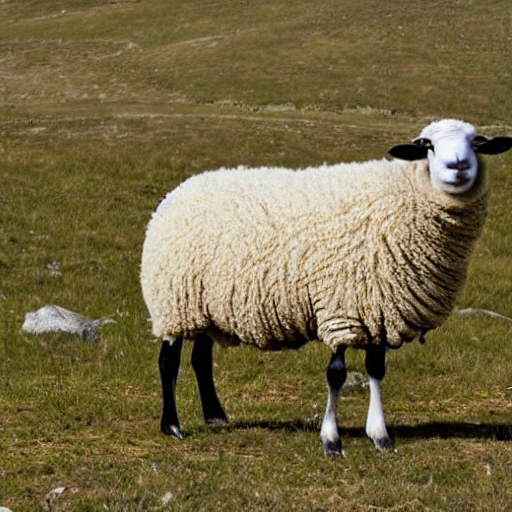

  0%|          | 0/50 [00:00<?, ?it/s]

Prompt 1: an old man with a long beard reading a book next to a window


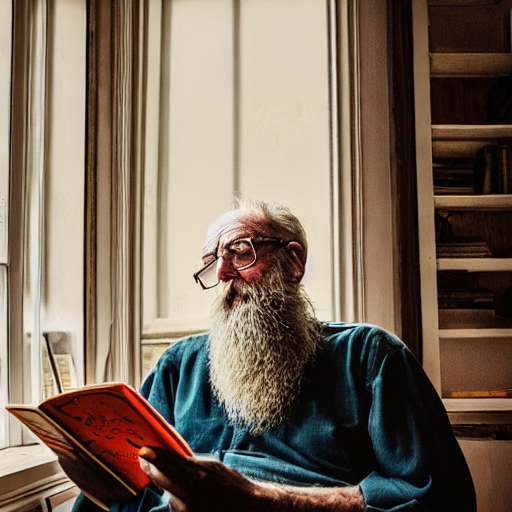

In [8]:
### imagenes antes del finetuning ####

prompts = [
    "an image of a sheep",
    "an old man with a long beard reading a book next to a window"
]
seed = 42

for i, prompt in enumerate(prompts):
    # Reiniciamos el generado en cada prompt
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(prompt, generator=generator).images[0]

    image.save(f"{carpeta_resultados}/antes_{i}.png")
    print(f"Prompt {i}: {prompt}")
    display(image)


In [9]:
# carga del dataset

dataset_name = "gigant/oldbookillustrations"

dataset = load_dataset(dataset_name, split="train", columns=["1600px", "info_alt"])

print(dataset)
print(f"Dataset con {len(dataset)} imágenes")


README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

data/train-00000-of-00013-c0326990f575de(…): reconstructing file:   0%|          |  0.00B /  628MB            

data/train-00000-of-00013-c0326990f575de(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-a511e1086f1718(…): reconstructing file:   0%|          |  0.00B /  439MB            

data/train-00001-of-00013-a511e1086f1718(…): downloading bytes:           |  0.00B            

... (20 outputs left out)

data/train-00012-of-00013-cf490ec155e3b8(…): reconstructing file:   0%|          |  0.00B /  388MB            

data/train-00012-of-00013-cf490ec155e3b8(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4154 [00:00<?, ? examples/s]

Dataset({
    features: ['1600px', 'info_alt'],
    num_rows: 4154
})
Dataset con 4154 imágenes


[0] tamaño (ancho, alto) = (1158, 1600), modo = RGB
  descripción: A bald man with a long beard smiles faintly as he carries on his back a little girl wearing his hat



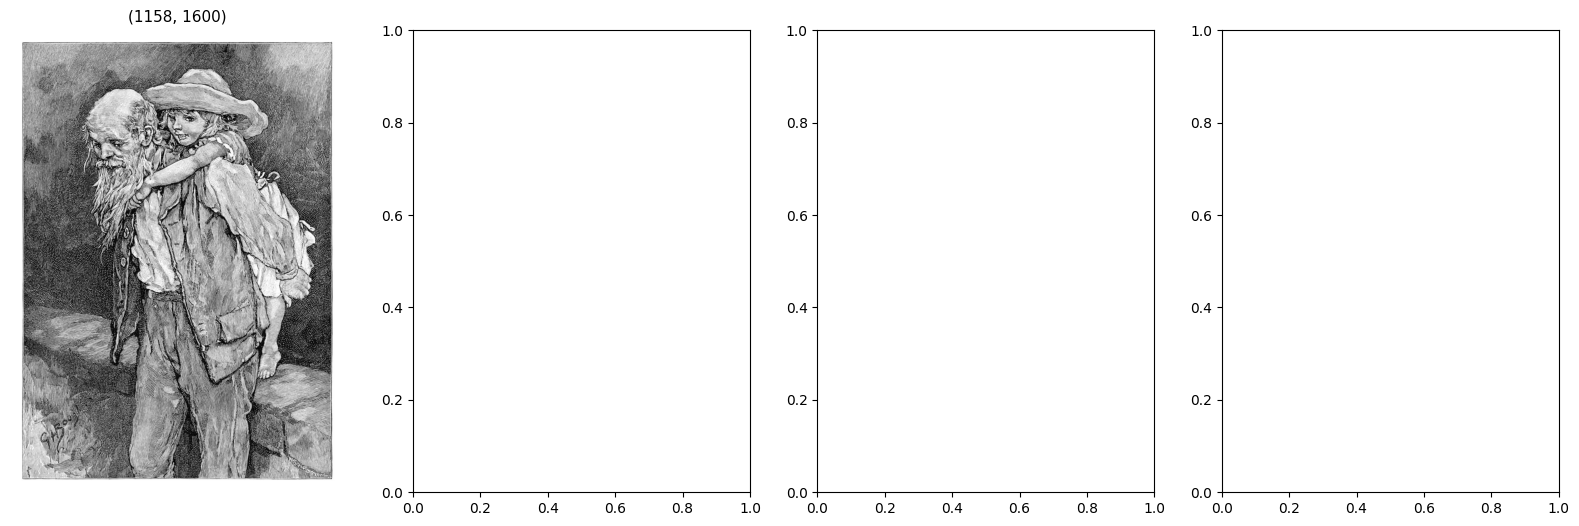

[1] tamaño (ancho, alto) = (1600, 1206), modo = RGB
  descripción: An old man with a long beard and tattered clothes wakes up outdoors and checks his head and his gun

[2] tamaño (ancho, alto) = (1263, 1600), modo = RGB
  descripción: A young man is drinking from a jug under the gaze of an older man filling another one from a keg

[3] tamaño (ancho, alto) = (1600, 1110), modo = RGB
  descripción: A young man has sat down by a tree to have something to eat, of which he gives a morsel to his dog



In [10]:
### ejemplos ####

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for i, ax in enumerate(axes):
    ejemplo = dataset[i]
    img = ejemplo["1600px"]
    texto = ejemplo["info_alt"] or ""

    print(f"[{i}] tamaño (ancho, alto) = {img.size}, modo = {img.mode}")
    print(f"  descripción: {texto[:120]}\n")

    ax.imshow(img.convert("RGB"))
    ax.set_title(f"{img.size}", fontsize=11)
    ax.axis("off")

    plt.show()


In [11]:
#### Transformaciones adaptadas #####

resolution = 512 # resolución del modelo

image_transforms = transforms.Compose([
    transforms.Resize(resolution),  # lado corto a 512, mantiene la proporción
    transforms.CenterCrop(resolution), # recorte central de 512x512
    transforms.ToTensor(), # PIL -> tensor
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]), # valores de [0,1] a [-1,1]
    ])
print(image_transforms)

Compose(
    Resize(size=512, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(512, 512))
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


Image 0: tamaño original (1158, 1600)


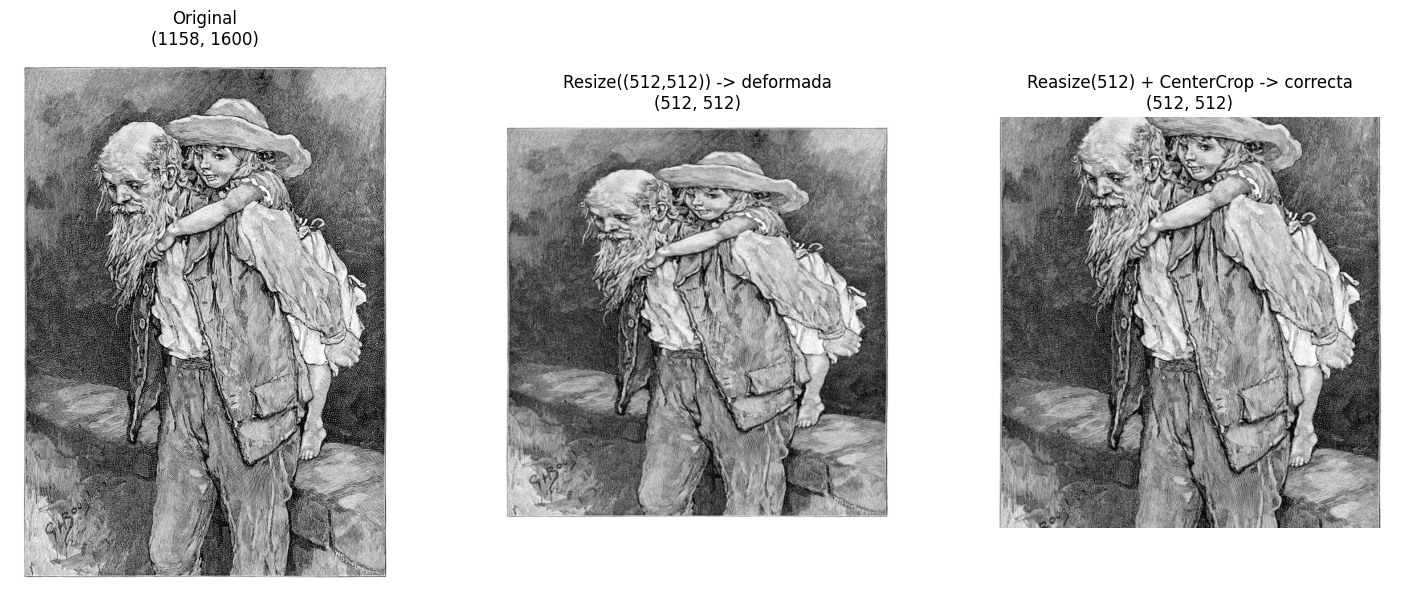

In [12]:
# Comprobación visual
# Buscamos una imagen claramente vertical para que se note la diferencia
for i in range(100):
    img = dataset[i]["1600px"]
    if img.height > 1.3 * img.width:
        break

original = img.convert("RGB")
print(f"Image {i}: tamaño original {original.size}")

deformada = transforms.Resize((resolution, resolution)) (original)
tensor = image_transforms(original)
correcta = transforms.ToPILImage()((tensor * 0.5 + 0.5).clamp(0, 1))

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
titulos = ["Original", "Resize((512,512)) -> deformada", "Reasize(512) + CenterCrop -> correcta"]
for ax, im, titulo in zip(axes, [original, deformada, correcta], titulos):
    ax.imshow(im)
    ax.set_title(f"{titulo}\n{im.size}")
    ax.axis("off")
plt.show()


LIBRERIA GPU

In [13]:
if "pipe" in globals():
    del pipe
torch.cuda.empty_cache()

In [14]:
#tokenizador
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
#scheduler
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
# text Encoder
text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder").to(device)
#VAE
vae= AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae").to(device)
# Unet
unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet").to(device)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [15]:
vae.eval()
text_encoder.eval()

for param in vae.parameters():
    param.requires_grad = False
for param in text_encoder.parameters():
    param.requires_grad = False

In [16]:
import math

#### panel de control ####

num_samples   = 600 #imagenes del dataset que usamos
batch_size    =  3 # imágenes por paso
num_epochs    =  5
lora_rank     =  6
lora_alpha    =  6
learning_rate =  1e-4

pasos_por_epoca = math.ceil(num_samples / batch_size)
print(f"{pasos_por_epoca} pasos por epoca, {pasos_por_epoca * num_epochs} pasos en total")
print(f"Tiempo estimado en T4: ~{pasos_por_epoca * num_epochs * 3.3 / 60:.0f} min")


200 pasos por epoca, 1000 pasos en total
Tiempo estimado en T4: ~55 min


In [17]:
train_data = dataset.shuffle(seed=42).select(range(num_samples))
print(train_data)

Dataset({
    features: ['1600px', 'info_alt'],
    num_rows: 600
})


In [18]:
class Text2ImageDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = image_transforms(example["1600px"].convert("RGB"))   # columna de la imagen
        caption = example["info_alt"] or ""                          # columna de la descripción
        token = tokenizer(caption, padding="max_length", truncation=True,
                          max_length=tokenizer.model_max_length, return_tensors="pt")
        return {
            "pixel_values": image,
            "input_ids": token.input_ids.squeeze(0),
            "attention_mask": token.attention_mask.squeeze(0),
        }

train_dataset = Text2ImageDataset(train_data)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Comprobación rápida de un ejemplo:
ejemplo = train_dataset[0]
print(ejemplo["pixel_values"].shape)   # debe salir torch.Size([3, 512, 512])
print(ejemplo["input_ids"].shape)      # debe salir torch.Size([77])

# Comprobación rápida de un ejemplo:
ejemplo = train_dataset[0]
print(ejemplo["pixel_values"].shape)   # debe salir torch.Size([3, 512, 512])
print(ejemplo["input_ids"].shape)      # debe salir torch.Size([77])


torch.Size([3, 512, 512])
torch.Size([77])
torch.Size([3, 512, 512])
torch.Size([77])


In [19]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [20]:
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name="oldbooks")

# Cuántos parámetros entrenamos realmente:
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parametros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

# Optimizador SOLO sobre la LoRA:
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

# Acelerador:
accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print(accelerator.device)

Parametros entrenables (LoRA): 1,195,776 de 860,716,740 (0.14%)
cuda


In [21]:
carpeta_lora = f"{carpeta_resultados}/lora"

def guardar_lora(carpeta):
    unet_sin_envoltorio = accelerator.unwrap_model(unet)
    lora_state_dict = convert_state_dict_to_diffusers(
        get_peft_model_state_dict(unet_sin_envoltorio, adapter_name="oldbooks")
    )
    StableDiffusionPipeline.save_lora_weights(
        save_directory=carpeta,
        unet_lora_layers=lora_state_dict,
        safe_serialization=True,
    )
    print(f"LoRA guardada en {carpeta}")

In [22]:
historial_loss = []

unet.train()
for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch}")
    loss_epoca = 0.0

    for batch in progress_bar:
        # Imagen -> espacio latente con el encoder del VAE:
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215

        # Difusión hacia delante: ruido + timestep aleatorio + añadir ruido
        noise = torch.randn_like(latents)
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                  (latents.shape[0],), device=latents.device).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Codificamos el texto:
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # La UNet (con LoRA) predice el ruido:
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # Error y actualización (solo LoRA):
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        loss_epoca += loss.item()
        progress_bar.set_postfix(loss=loss.item())

    # Al terminar cada época: loss media y guardado en Drive
    media = loss_epoca / len(train_dataloader)
    historial_loss.append(media)
    print(f"Época {epoch}: loss media = {media:.4f}")
    guardar_lora(f"{carpeta_lora}/epoca_{epoch}")

Epoch 0: 100%|██████████| 200/200 [13:43<00:00,  4.12s/it, loss=0.474]


Época 0: loss media = 0.1451
LoRA guardada en /content/drive/MyDrive/entrega_lora_oldbooks/lora/epoca_0


Epoch 1: 100%|██████████| 200/200 [13:43<00:00,  4.12s/it, loss=0.202]


Época 1: loss media = 0.1436
LoRA guardada en /content/drive/MyDrive/entrega_lora_oldbooks/lora/epoca_1


Epoch 2: 100%|██████████| 200/200 [13:40<00:00,  4.10s/it, loss=0.132]


Época 2: loss media = 0.1480
LoRA guardada en /content/drive/MyDrive/entrega_lora_oldbooks/lora/epoca_2


Epoch 3:   0%|          | 0/200 [00:03<?, ?it/s]


KeyboardInterrupt: 

In [27]:
num_epochs = len(historial_loss)
print(num_epochs)

3


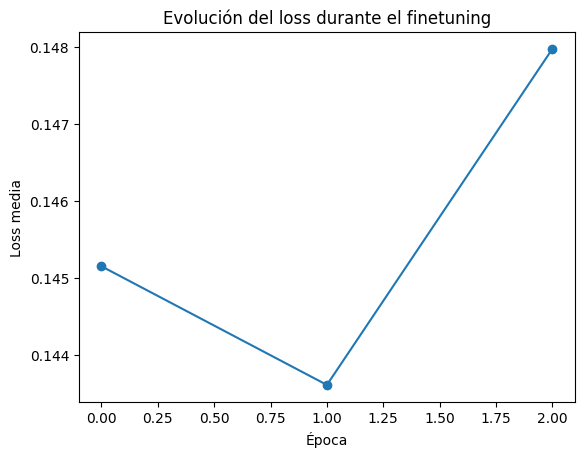

In [28]:
plt.plot(range(num_epochs), historial_loss, marker="o")
plt.xlabel("Época")
plt.ylabel("Loss media")
plt.title("Evolución del loss durante el finetuning")
plt.show()

(0.0, 0.2)

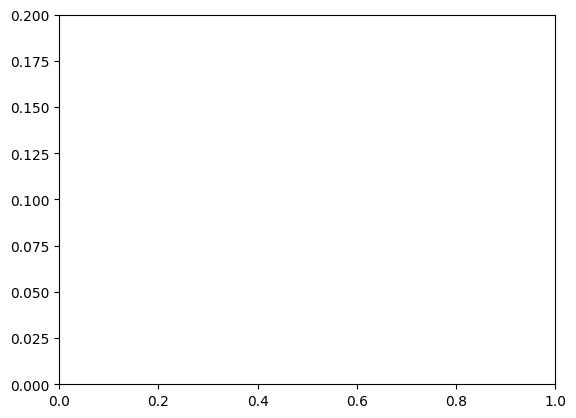

In [29]:
plt.ylim(0, 0.2)

In [30]:
unet = accelerator.unwrap_model(unet)
unet.eval()

pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
).to(device)

pipe.set_adapters(["oldbooks"], adapter_weights=[1.0])
print("Pipeline con LoRA listo!")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline con LoRA listo!


  0%|          | 0/50 [00:00<?, ?it/s]

Prompt 0: an image of a sheep


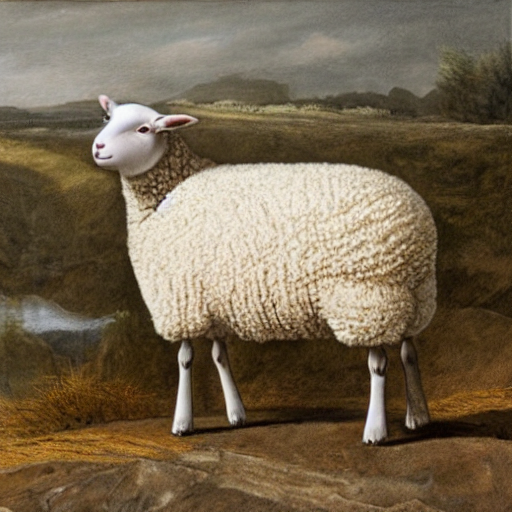

  0%|          | 0/50 [00:00<?, ?it/s]

Prompt 1: an old man with a long beard reading a book next to a window


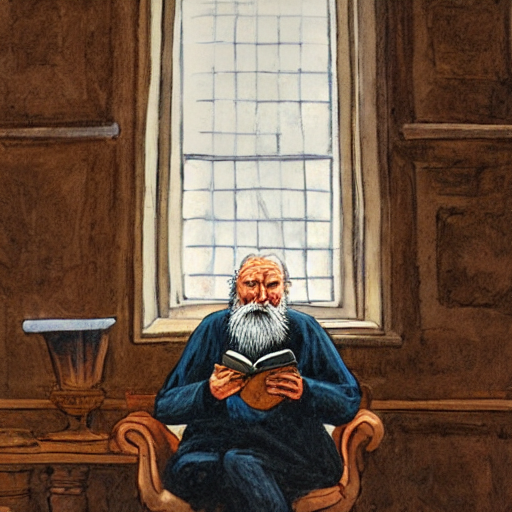

In [31]:
for i, prompt in enumerate(prompts):
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(prompt, generator=generator).images[0]

    image.save(f"{carpeta_resultados}/despues_{i}.png")
    print(f"Prompt {i}: {prompt}")
    display(image)

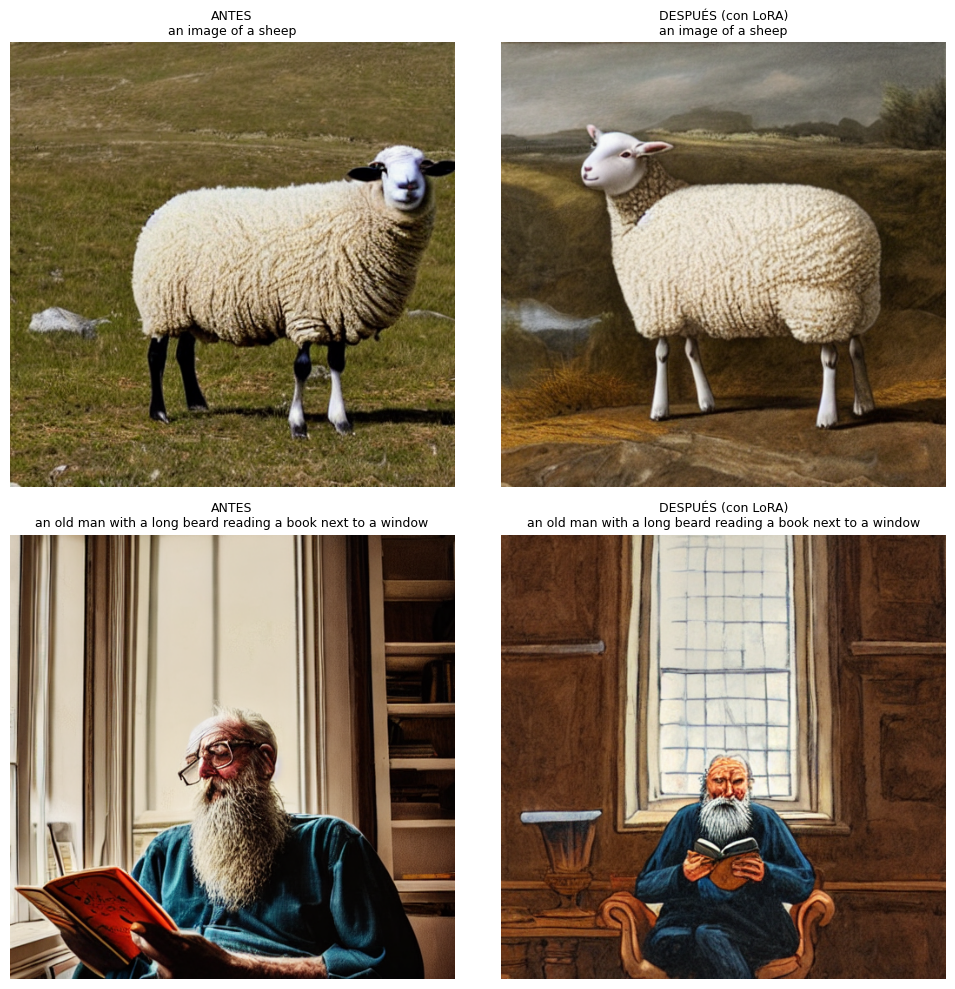

In [32]:
fig, axes = plt.subplots(len(prompts), 2, figsize=(10, 5 * len(prompts)))

for i, prompt in enumerate(prompts):
    antes = Image.open(f"{carpeta_resultados}/antes_{i}.png")
    despues = Image.open(f"{carpeta_resultados}/despues_{i}.png")

    axes[i, 0].imshow(antes)
    axes[i, 0].set_title(f"ANTES\n{prompt}", fontsize=9)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(despues)
    axes[i, 1].set_title(f"DESPUÉS (con LoRA)\n{prompt}", fontsize=9)
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(f"{carpeta_resultados}/comparacion_antes_despues.png", dpi=100)
plt.show()

In [34]:
from huggingface_hub import notebook_login
notebook_login()

In [35]:
from huggingface_hub import HfApi, create_repo
import shutil

api = HfApi()
usuario = api.whoami()["name"]
repo_id = f"{usuario}/sd-v1-4-lora-oldbookillustrations"
create_repo(repo_id, exist_ok=True)

# Carpeta con lo que subiremos

carpeta_hf = f"{carpeta_resultados}/hf_repo"
guardar_lora(carpeta_hf)
shutil.copy(f"{carpeta_resultados}/comparacion_antes_despues.png", carpeta_hf)

readme = f"""---
base_model: {pretrained_model_name}
datasets:
- gigant/oldbookillustrations
library_name: diffusers
tags:
- stable-diffusion
- lora
- text-to-image
---

# Stable Diffusion v1.4 + LoRA (ilustraciones de libros antiguos)

Finetuning con LoRA de `{pretrained_model_name}` usando el dataset
`gigant/oldbookillustrations` (columnas `1600px` e `info_alt`).

## Hiperparámetros
- Imágenes: {num_samples} | Épocas: {num_epochs} | Batch: {batch_size}
- LoRA r = {lora_rank}, alpha = {lora_alpha} | Learning rate: {learning_rate}
- Resolución: {resolution} (Resize del lado corto + CenterCrop)

## Cómo usarlo
Modelo base + LoRA:
~~~python
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("{pretrained_model_name}").to("cuda")
pipe.load_lora_weights("{repo_id}")
image = pipe("an old man reading a book").images[0]
~~~

Modelo completo (LoRA ya fusionada):
~~~python
pipe = StableDiffusionPipeline.from_pretrained("{repo_id}").to("cuda")
~~~

## Antes / después (mismo prompt y semilla)
![comparación](comparacion_antes_despues.png)
"""

with open(f"{carpeta_hf}/README.md", "w") as f:
    f.write(readme)

print("Repositorio:", f"https://huggingface.co/{repo_id}")
print("Archivos preparados:", os.listdir(carpeta_hf))


LoRA guardada en /content/drive/MyDrive/entrega_lora_oldbooks/hf_repo
Repositorio: https://huggingface.co/Roxana80/sd-v1-4-lora-oldbookillustrations
Archivos preparados: ['pytorch_lora_weights.safetensors', 'comparacion_antes_despues.png', 'README.md']


In [36]:
# subirlo a lora

api.upload_folder(
    folder_path=carpeta_hf,
    repo_id=repo_id,
    commit_message="LoRA entrenada con oldbookillustrations",
)
print(f"Subido: https://huggingface.co/{repo_id}")

Subido: https://huggingface.co/Roxana80/sd-v1-4-lora-oldbookillustrations


In [37]:
# 1) Fusionamos la LoRA dentro de los pesos de la UNet (W = W0 + B·A)
pipe.fuse_lora(components=["unet"], lora_scale=1.0)

# 2) Quitamos las capas LoRA sueltas (ya están "dentro" de los pesos)
pipe.unload_lora_weights()

# 3) Pasamos a float16 para que ocupe la mitad (~2,7 GB en vez de ~5,5 GB)
pipe = pipe.to(torch.float16)

# 4) Guardamos en el disco de Colab (no en Drive, pesa mucho) y subimos
carpeta_completo = "/content/modelo_completo"
pipe.save_pretrained(carpeta_completo)

api.upload_folder(
    folder_path=carpeta_completo,
    repo_id=repo_id,
    commit_message="Modelo completo con la LoRA fusionada (fp16)",
)
print("Modelo completo subido")

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo completo subido


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B / 4.82MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/50 [00:00<?, ?it/s]

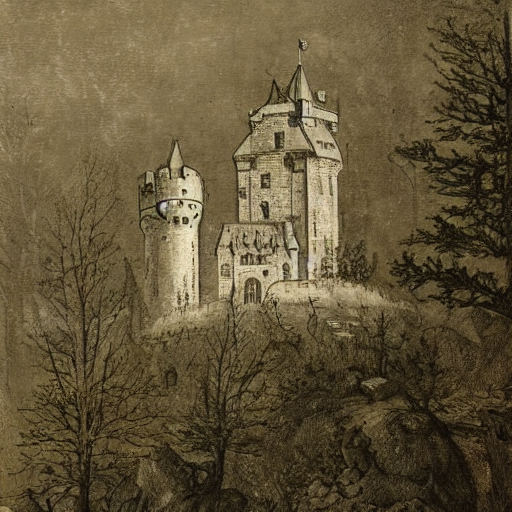

In [38]:
# Liberamos la GPU
del pipe
torch.cuda.empty_cache()

# Modelo base + LoRA descargada de tu repositorio
pipe_hf = StableDiffusionPipeline.from_pretrained(pretrained_model_name, torch_dtype=torch.float16).to(device)
pipe_hf.load_lora_weights(repo_id, adapter_name="oldbooks")
pipe_hf.set_adapters(["oldbooks"], adapter_weights=[1.0])

prompt_nuevo = "a castle on a hill surrounded by a dark forest"
generator = torch.Generator(device=device).manual_seed(seed)
image = pipe_hf(prompt_nuevo, generator=generator).images[0]

image.save(f"{carpeta_resultados}/desde_hf.png")
display(image)

In [39]:
with open(f"{carpeta_resultados}/link_huggingface.txt", "w") as f:
    f.write(f"https://huggingface.co/{repo_id}\n")

print(open(f"{carpeta_resultados}/link_huggingface.txt").read())

https://huggingface.co/Roxana80/sd-v1-4-lora-oldbookillustrations

